# Experiment 09: BatchNorm

Card: [exp09_batch_norm.md](../../experiments/exp09_batch_norm.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import INK, SURFACE, TEXT, style_axis
from ashrae.tracking import session_runs
from src.data import fold_loaders
from src.networks import MeterMLP
from src.runs import finished_keys, fold_table, scores_at_best, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp09_batch_norm"
EMB_DIM = 12  # picked in exp03
LRS = [
    2.5e-3,
    5e-3,
    1e-2,
    2e-2,
    4e-2,
]  # first and last trained only if the best inner rate is next to them
if SMOKE:
    EXPERIMENT = "ashrae-mlp-batch-norm-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS, WINDOW = 3, 1
    # without BatchNorm (Adam lr 1e-2, batch 4096) and its seconds per epoch; None: the latest session
    REFERENCE = ("ashrae-mlp-optimizers-smoke", None)
    TIMING = ("ashrae-mlp-batch-size-smoke", None)
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-batch-norm"
    TRAIN = False  # the runs below are from 2026-10-12; True resumes this session, retraining unfinished runs
    SESSION = "2026-10-12 21:52:51"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WINDOW = (
        5  # epochs before the best one over which the epoch-to-epoch change is averaged
    )
    REFERENCE = ("ashrae-mlp-optimizers", "2026-10-12 13:42:10")  # exp05
    TIMING = ("ashrae-mlp-batch-size", "2026-10-12 15:01:13")  # exp04
    FIGURE = "../../figures/exp09_batch_norm.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-batch-norm', session 2026-10-12 21:52:51


## Training


In [2]:
def at_best(run_id):
    """`scores_at_best`, plus the mean change of validation RMSLE per epoch over the WINDOW epochs up to the best."""
    s = scores_at_best(experiment, run_id)
    if np.isfinite(s["val"]):
        b = s["best_epoch"] - 1
        val = s["val_curve"]
        s["change"] = np.abs(np.diff(val[max(b - WINDOW, 0) : b + 1])).mean() if b else np.nan
    return s


def scores():
    ref = session_runs(*REFERENCE)
    ref = ref[
        (ref.model == "mlp_4out_emb")
        & (ref.optimizer == "Adam")
        & (ref.lr.astype(float) == 1e-2)
    ]
    results = session_scores(
        experiment,
        {"batch_norm": bool, "lr": float},
        FOLD_NAMES,
        [ref.assign(batch_norm=False)],
        at_best=at_best,
        own={"batch_norm": True},
    )
    # the reference runs didn't log timing; epoch time doesn't depend on Adam's rate
    timing = session_runs(*TIMING)
    timing = timing[timing.batch_size.astype(int) == 4096].run_id
    seconds = np.mean([np.mean(experiment.history(r, "epoch_seconds")) for r in timing])
    results["epoch_seconds"] = results.epoch_seconds.fillna(seconds)
    results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60
    return results

In [3]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = set() if SESSION is None else finished_keys(scores().query("batch_norm"), ["lr", "fold"])

    def train(lr):
        fit_folds(
            experiment,
            folds,
            lambda: MeterMLP(n_features, n_buildings, emb_dim=EMB_DIM, batch_norm=True),
            f"mlp_4out_emb_bn | lr {lr:g}",
            done=done,
            key=(lr,),
            epochs=EPOCHS,
            lr=lr,
            tags={"model": "mlp_4out_emb_bn", "lr": f"{lr:g}"},
            params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM},
        )

    for lr in LRS[1:-1]:
        train(lr)
    bn = scores().query("batch_norm")
    best = bn[bn.lr.isin(LRS[1:-1])].groupby("lr").val.mean().idxmin()
    if best in (LRS[1], LRS[-2]):
        train(LRS[0] if best == LRS[1] else LRS[-1])

## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "change": f"change over {WINDOW} epochs before best",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
table, by_setup = fold_table(results, ["batch_norm", "lr"], columns, FOLD_NAMES)
display(table.round(3))

MLflow session 2026-10-12 21:52:51: 20 runs, with the reused ones


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
batch_norm lr                                                               
False      0.010                                  1.399    1.204    1.011   
True       0.005                                  1.394    1.201    1.010   
           0.010                                  1.386    1.195    1.008   
           0.020                                  1.390    1.192    1.004   
           0.040                                  1.381    1.198    1.011   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
batch_norm lr                                                      
False      0.010                                  1.090    1.176   
True       0.005                                  1.091    1.174   
           0.010                                  1.085    1.168   
           0.020                                  1.086    1.168   
           0.040                                  1.087    1.169   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
batch_norm lr                                                         
False      0.010                                              0.913   
True       0.005                                              0.915   
           0.010                                              0.912   
           0.020                                              0.908   
           0.040                                              0.914   

RMSLE at the best epoch, all rows unless noted  best epoch  training  \
batch_norm lr                                                          
False      0.010                                     29.00     0.773   
True       0.005                                     26.75     0.774   
           0.010                                     35.25     0.761   
           0.020                                     36.75     0.756   
           0.040                                     28.00     0.765   

RMSLE at the best epoch, all rows unless noted  change over 5 epochs before best  \
batch_norm lr                                                                      
False      0.010                                                           0.007   
True       0.005                                                           0.007   
           0.010                                                           0.013   
           0.020                                                           0.012   
           0.040                                                           0.013   

RMSLE at the best epoch, all rows unless noted  seconds per epoch  \
batch_norm lr                                                       
False      0.010                                            1.717   
True       0.005                                            2.089   
           0.010                                            2.098   
           0.020                                            2.175   
           0.040                                            2.151   

RMSLE at the best epoch, all rows unless noted  minutes to best epoch  
batch_norm lr                                                          
False      0.010                                                0.830  
True       0.005                                                0.931  
           0.010                                                1.232  
           0.020                                                1.330  
           0.040                                                1.001

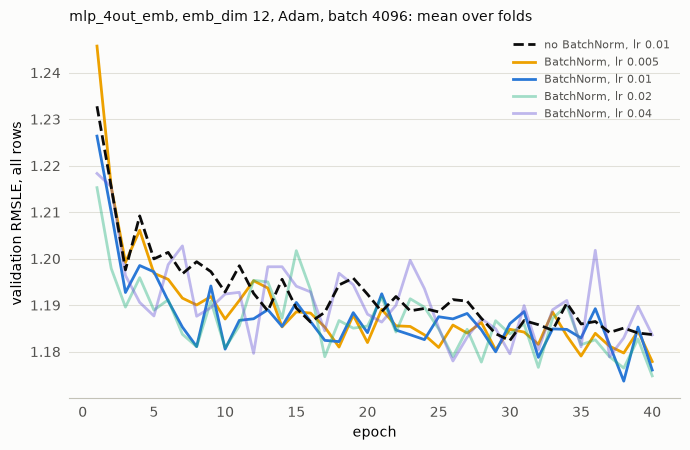

In [5]:
SHADES = {
    2.5e-3: "#e87ba4",
    5e-3: "#eda100",
    1e-2: "#2a78d6",
    2e-2: "#1baf7a",
    4e-2: "#6250d6",
}

fig, ax = plt.subplots(figsize=(7, 4.6), facecolor=SURFACE)
for (batch_norm, lr), runs in results.groupby(["batch_norm", "lr"]):
    curve = pd.DataFrame(
        runs.val_curve.tolist()
    ).mean()  # mean over folds; a diverged run is shorter
    ax.plot(
        np.arange(1, len(curve) + 1),
        curve,
        lw=2,
        color=SHADES[lr] if batch_norm else INK,
        ls="-" if batch_norm else "--",
        alpha=0.4 if batch_norm and lr in (2e-2, 4e-2) else 1,
        zorder=2 if batch_norm else 3,  # no BatchNorm on top
        label=f"BatchNorm, lr {lr:g}" if batch_norm else f"no BatchNorm, lr {lr:g}",
    )
ax.set(xlabel="epoch", ylabel="validation RMSLE, all rows")
ax.set_title(
    f"mlp_4out_emb, emb_dim {EMB_DIM}, Adam, batch 4096: mean over folds",
    loc="left",
    color=INK,
    fontsize=10,
)
style_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=TEXT)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("batch_norm").run_id:
        experiment.client.log_artifact(run_id, FIGURE)